# Expanding a square wave as a Fourier series

## Introduction:
Fourier's theorem says that any periodic function can be decomposed into a sum of sine and cosine functions. In this notebook, I'll vary the value of n_max we used in the series, which will enable us to visualise how the square wave is built up from sine waves of different frequencies and amplitudes.(1) 

<div class="alert alert-success">
<h2> The task: </h2>
<br>
This is a template for the unit 7 Fourier Square Wave task. Your job is to fill in the blanks in the code and add text cells where needed. 
<br>
All the instructions for the task are in green text cells like this one. You can keep these cells in your submitted notebook if you want, but they will be ignored by the markers.
<br>
You will be graded on your completed code, and the text cells that you add yourself. Some template text cells are already added, but feel free to add more.
</div>

<div class="alert alert-success">
Replace the title/header of this notebook with your own title, and include a suitable introduction. (You can leave this until the end, but don't forget!)
<div>

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# The line below changes the default figure size. 
# You may want to edit it to taste or comment it out depending on the size of your screen.
# Don't make the figure so large that you also need to adjust the text size though!
# The default proportions are there for a reason.
plt.rcParams['figure.figsize'] = 12, 6

<div class="alert alert-success">
The code cell below defines our initial data. A value for $L$, the half-period of the function, has already been set. Add a line that will create an array, named <tt>x</tt>, of values to use for the x-values for the plot from $-10$ to $+10$, with an appropriate number of points to result in a smooth function on the plot. (You can come back and adjust this later).
<div>


In [10]:
### Set up initial data
L = 5.     # period of the function is [−L,L]
##### STUDENT COMPLETED LINE #####
x=np.linspace(-10,10,201)
###################################

<div class="alert alert-success">
The code cell below contains the start of a function that needs to calculate the Fourier series for a square wave, i.e. it codes the mathematical function
$$f_\text{square}(x) = \frac{4}{\pi} \sum_{n = 1, 3, 5, \ldots}^{\infty} \frac{1}{n} \sin\left(\frac{n \pi x}{L}\right) \qquad \qquad (1)$$ 
for all $n$ up to and including $n = $ <tt>n_max</tt> (as we will need to truncate our series at some finite point rather than continuing all the way to $n = \infty$). The docstring has already been written for you.

<ul>
<li>
Complete the function to calculate the Fourier series including the terms for all values of $n$ up to <tt>n_max</tt> specified in the function input. </li>
<li> <b>Don't change any of the variable names or the docstring. </b>Follow the specification given. </li>
<li>Use appropriate code comments to explain how your function works.</li>
</ul>

<b> Note:</b> Here the variable <tt>L</tt> will act as a _global_ variable. It is defined in the cell above, and when you reference <tt>L</tt> in your function it will use that value of <tt>L</tt>, without having to explicitly pass it to the function. In other words, you don't need to redefine <tt>L</tt> within your function.

<b> HINTS:</b> You will need to use a loop, as you did in the series summation task in module 6. Think carefully about the differences and similarities between that summation and this one. In particular:
<ul>
<li>What are the start and end points of the summation?</li>
<li>Are we summing over all values of n? How will you deal with this?</li>
<li>Note that we're going to be calculating this for an array of x-values. However, as we saw in the Legendre polynomial example, this doesn't make any difference to the way the function is coded: it will automatically work either for a single x-value or an array.</li>
</ul>

<div>

In [11]:
def fourier_square(x,n_max):
    '''Creates the Fourier series for square wave.
    Inputs:
    x:       array of x-values or single x-value
    n_max:   maximum value of n in summation from eqn(1) above
    Depends on:
    L:       global variable determining period of square wave
    Returns:
    fourier: array of y-values or single y-value for Fourier square wave
    
    '''
    #### STUDENT COMPLETED CELL ####
    # Write code here to satisfy the specification given 
    # in the docstring.
    #set L as a global variable
    global L

    #calculate $f_\text{square}(x) = \frac{4}{\pi} \sum_{n = 1, 3, 5, \ldots}^{\infty} \frac{1}{n} \sin\left(\frac{n \pi x}{L}\right)$
    fourier=0
    for n in range (1,n_max+1,2):
        fourier+=(1/n)*np.sin((n*np.pi*x)/L)
    fourier=fourier*4/np.pi

    #return calculated value
    return fourier
    ################################

<div class="alert alert-success">
The code cell below will allow you to check that your <tt>fourier_square</tt> function is working correctly. Does it generate the correct output for the given inputs? You should debug your function before proceeding. However, if you can't find the source of any problem it may be worth also writing the code that will plot the Fourier series (below), in case looking at a plot of the function over the whole x-range reveals the source of the problem.
</div>

In [12]:
# Check all is well before proceeding!
print(f"At x = 5 and n_max = 1, function returns {fourier_square(5,1)}.")
print("  Should be zero.")
print(f"At x = -2 and n_max = 7, function returns {fourier_square(-2,7)}.")
print("  Should be -1.06837....")

At x = 5 and n_max = 1, function returns 1.5592687330077502e-16.
  Should be zero.
At x = -2 and n_max = 7, function returns -1.0683720178191634.
  Should be -1.06837....


<div class="alert alert-success">
Now you should use your function to plot the Fourier series for different numbers of terms, investigate its behaviour, and write some conclusions. You may want to go further, but you should at least look at, and comment on what happens
<ul>
    <li>as <tt>n_max</tt> increases;</li>
    <li>when <tt>n_max</tt> changes between odd and even values, e.g. from 1 to 2, 2 to 3, and 3 to 4;</li>
    <li>when <tt>n_max</tt> becomes very large, say over 100;</li>
    <li>in regions where the function is changing rapidly.</li>
</ul>
You should think about how best to present your results, e.g. whether to plot different results on the same axes or separate ones. You can add further code and text cells as appropriate.
<div>

In [13]:
#### STUDENT COMPLETED CELL ##########
# Add your code here.
# You may also add further code cells.


def plot_figure(x,n_max):
    '''input     
    x:       array of x-values or single x-value
    n_max:   maximum value of n in summation from eqn(1) above
    and this function will plot the graph for those parameters'''
    #initialise figure
    plt.figure()
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Fourier series for a square wave')

    #get y values by function fourier_square
    y=fourier_square(x,n_max)

    #plot figure
    plt.plot(x,y,'-')

######################################

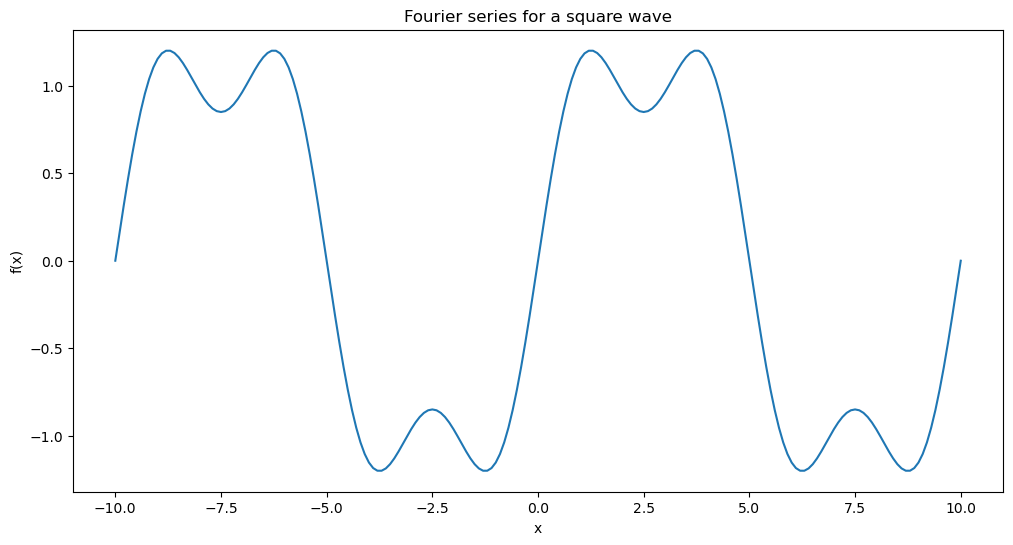

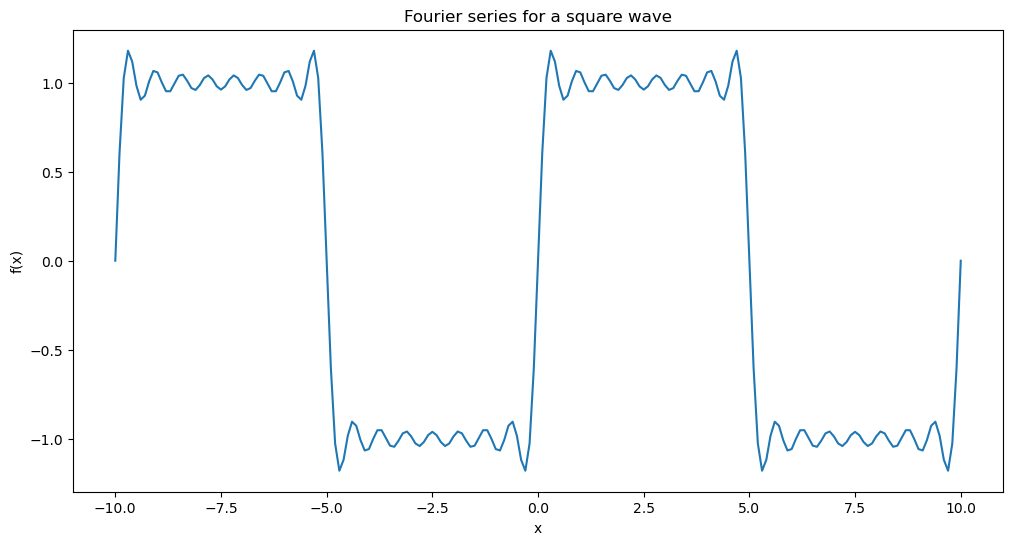

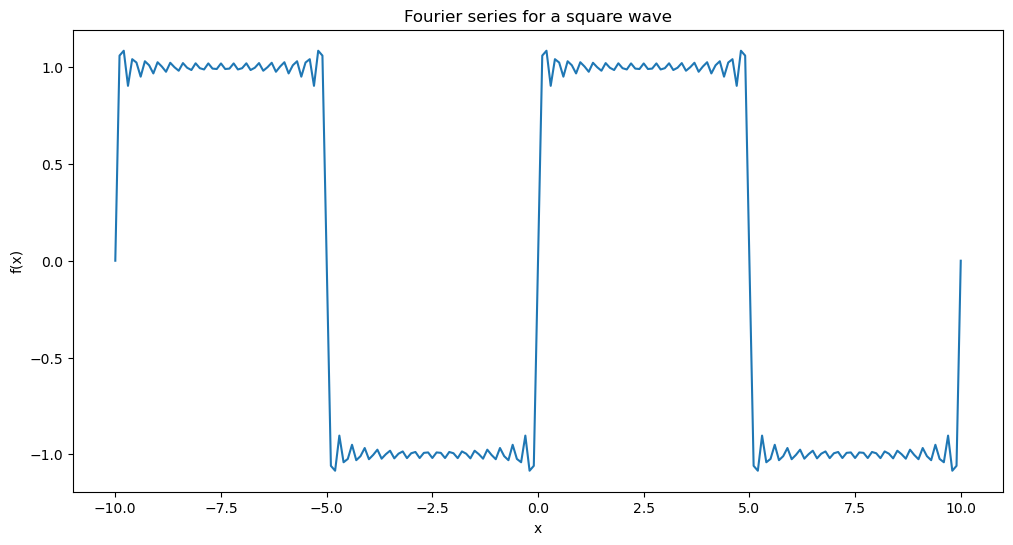

In [14]:
plot_figure(x,3)
plot_figure(x,15)
plot_figure(x,33)

it is obvious that, as the value of n_max increase, the figure become flatter

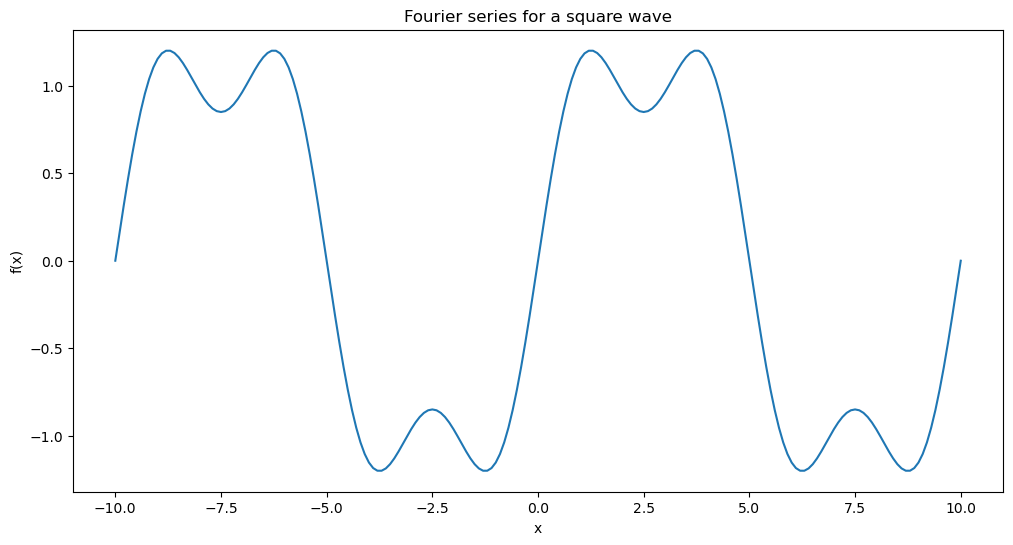

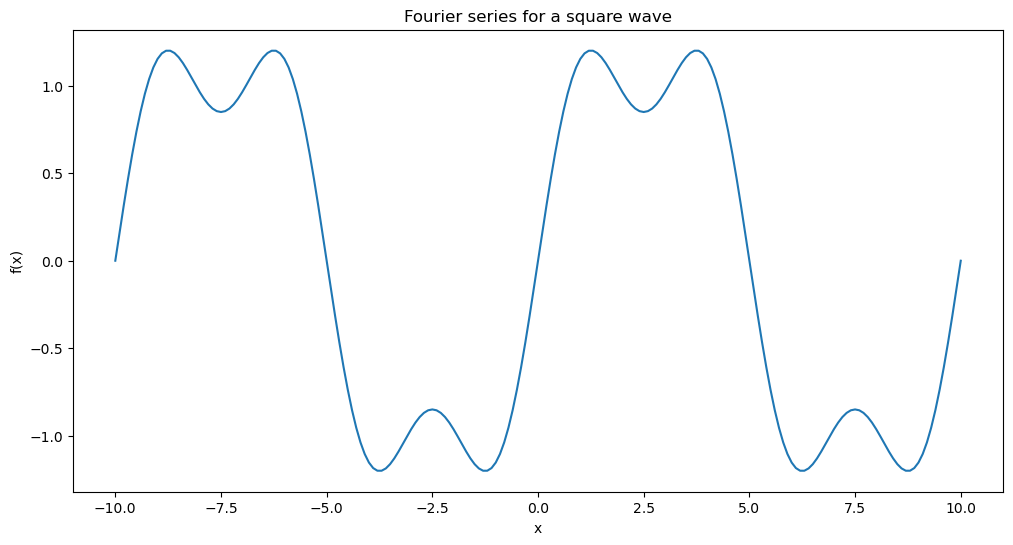

In [21]:
plot_figure(x,3)
plot_figure(x,4)

it is hard to find the differences of figure when the n_max changes from 3 to 4, so i would say there is no differences between them

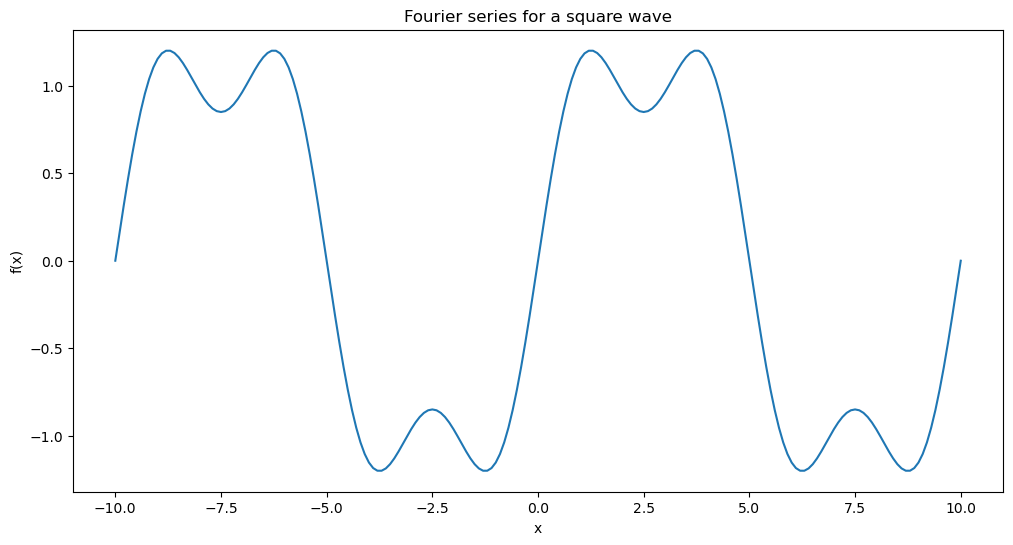

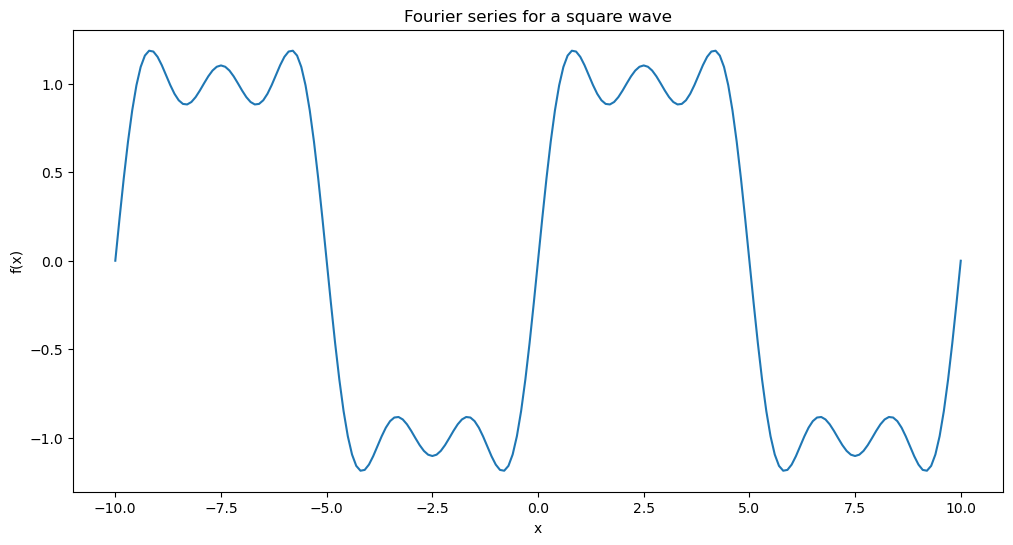

In [22]:
plot_figure(x,4)
plot_figure(x,5)

the number of vertice increase by 1, so when n_max change from odd to even, almost no change. when n_max change from even to odd, the vertice increase by 1

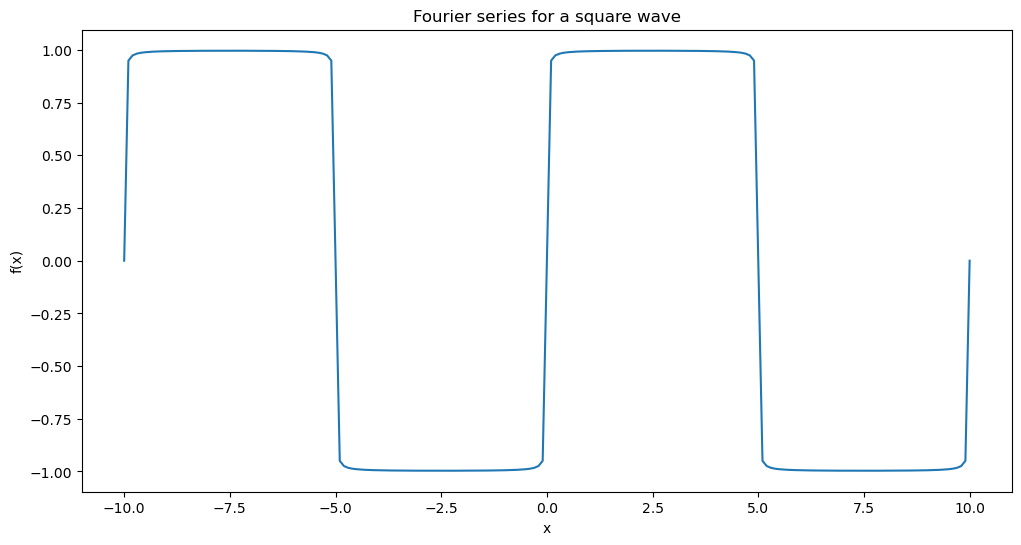

In [16]:
plot_figure(x,200)

when the n_max become very large, the figure can be approximately regarded as composed of straight lines

for the region that function is changing rapidly, it is due to the sign of $\sin\left(\frac{n \pi x}{L}\right)$ changes, and the values of function before next change in signal are almost the same.

YOU NEED TO COMPLETE THIS TEXT CELL, AND YOU MAY ADD FURTHER TEXT CELLS.

## Reference:
1:Unit7TaskIntroduction